# Анализ маркетплейса Olist: почему выручка стоит на месте

**Задача.** Продакт-менеджер Петя попросил разобраться, почему выручка перестала расти, и предложить, что с этим делать.

**Данные.** Публичный датасет Olist (Бразилия, 2016–2018): заказы, клиенты, товарные позиции. Скачать можно на [Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), три CSV нужно положить в папку `data/`.

**План:**
1. Подготовка данных и проверка полноты месяцев
2. Когортный анализ и месячный retention
3. Оценка Product/Market Fit
4. Ключевые метрики по месяцам
5. RFM-сегментация клиентов
6. Приоритизация гипотез по ICE
7. Метрики и дизайн эксперимента для выбранной гипотезы
8. Итоговый отчёт и самопроверка

> **Версия 2.** Перепроверив первую версию, я нашёл в ней методологические ошибки и пересчитал анализ. Что именно изменилось, описано в разделе «Самопроверка» в конце.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statistics import NormalDist
import warnings
warnings.filterwarnings('ignore')

DATA_PATH = Path('data')    # сюда положить CSV с Kaggle
IMG_PATH = Path('images')   # сюда сохраняются графики
IMG_PATH.mkdir(exist_ok=True)

customers   = pd.read_csv(DATA_PATH / 'olist_customers_dataset.csv')
orders      = pd.read_csv(DATA_PATH / 'olist_orders_dataset.csv')
order_items = pd.read_csv(DATA_PATH / 'olist_order_items_dataset.csv')

print(f'customers:   {customers.shape}')
print(f'orders:      {orders.shape}')
print(f'order_items: {order_items.shape}')

customers:   (99441, 5)
orders:      (99441, 8)
order_items: (112650, 7)


## 1. Подготовка данных

После загрузки трёх таблиц я заметил, что в `customers` и `orders` одинаковое количество строк: 99 441. Значит, `customer_id` создаётся заново для каждого заказа. Чтобы отслеживать одного и того же клиента, дальше я использую `customer_unique_id`.

In [2]:
print(orders['order_status'].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


Большая часть заказов доставлена: 96 478 из 99 441. В первой версии я работал только с `delivered`. Ниже видно, почему этого недостаточно.

In [3]:
print(orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


Пропуски есть только в датах одобрения и доставки. Это ожидаемо: у недоставленных и отменённых заказов этих дат ещё нет. Для анализа нужна только дата покупки, а в ней пропусков нет.

### Полнота данных по месяцам

Прежде чем считать retention и выручку по месяцам, проверяю, все ли месяцы в данных полные. Неполный месяц на краю периода легко принять за падение метрики.

In [4]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_month'] = orders['order_purchase_timestamp'].dt.to_period('M')

status_by_month = orders.pivot_table(
    index='order_month', columns='order_status',
    values='order_id', aggfunc='count', fill_value=0
)
status_by_month['всего'] = status_by_month.sum(axis=1)
status_by_month['не доставлено'] = status_by_month['всего'] - status_by_month['delivered']
status_by_month[['delivered', 'не доставлено', 'всего']]

order_status,delivered,не доставлено,всего
order_month,,,
2016-09,1,3,4
2016-10,265,59,324
2016-12,1,0,1
2017-01,750,50,800
2017-02,1653,127,1780
2017-03,2546,136,2682
2017-04,2303,101,2404
2017-05,3546,154,3700
2017-06,3135,110,3245


Таблица показывает две проблемы:
- **Начало периода неполное.** С сентября по декабрь 2016 года всего 329 заказов, а ноября 2016 в данных нет совсем. Это запуск площадки, а не её обычная работа.
- **Конец периода обрезан.** В сентябре и октябре 2018 года всего 20 заказов, и ни одного доставленного. Выгрузка фактически заканчивается в августе 2018.

Поэтому дальше анализирую **окно с января 2017 по август 2018** (20 полных месяцев). Беру все состоявшиеся заказы, то есть всё, кроме `canceled` и `unavailable`. Заказы в статусах `shipped`, `invoiced`, `processing` — это реальные покупки, которые просто ещё не доехали до клиента. Если их выбросить, последние месяцы выглядят хуже, чем на самом деле.

In [5]:
FIRST_MONTH = pd.Period('2017-01', 'M')
LAST_MONTH  = pd.Period('2018-08', 'M')


def months_between(later, earlier):
    """Сколько полных календарных месяцев между двумя месяцами (Period)."""
    return (later.dt.year - earlier.dt.year) * 12 + (later.dt.month - earlier.dt.month)


valid_orders = orders[~orders['order_status'].isin(['canceled', 'unavailable'])].merge(
    customers[['customer_id', 'customer_unique_id']], on='customer_id'
)

# Месяц первой покупки считаю по всей истории, чтобы клиент 2016 года не попал в когорты 2017-го как новый
valid_orders['cohort_month'] = valid_orders.groupby('customer_unique_id')['order_month'].transform('min')
valid_orders['period'] = months_between(valid_orders['order_month'], valid_orders['cohort_month'])

in_window = (valid_orders['order_month'] >= FIRST_MONTH) & (valid_orders['order_month'] <= LAST_MONTH)
window_orders = valid_orders[in_window].copy()                                   # все заказы окна
orders_full = window_orders[window_orders['cohort_month'] >= FIRST_MONTH].copy()  # заказы когорт окна

print('заказов в окне анализа:', len(window_orders))
print('клиентов в когортах окна:', orders_full['customer_unique_id'].nunique())

заказов в окне анализа: 97910
клиентов в когортах окна: 94697


## 2. Когортный анализ

Для каждого клиента определил месяц первой покупки (когорту) и посчитал, сколько месяцев прошло от него до каждого заказа (период).

In [6]:
cohort_data = orders_full.groupby(['cohort_month', 'period'])['customer_unique_id'].nunique().reset_index()
cohort_data.columns = ['cohort_month', 'period', 'n_customers']

cohort_sizes = cohort_data[cohort_data['period'] == 0][['cohort_month', 'n_customers']]
cohort_sizes.columns = ['cohort_month', 'cohort_size']
# Сколько периодов когорта успела «прожить» до конца данных
cohort_sizes['max_period'] = (LAST_MONTH.year - cohort_sizes['cohort_month'].dt.year) * 12 + \
                             (LAST_MONTH.month - cohort_sizes['cohort_month'].dt.month)

cohort_data = cohort_data.merge(cohort_sizes, on='cohort_month')
cohort_data['retention'] = cohort_data['n_customers'] / cohort_data['cohort_size'] * 100

# Взвешенный retention: все вернувшиеся / все клиенты когорт, которые успели дожить до этого периода
rows = []
for p in range(cohort_sizes['max_period'].max() + 1):
    eligible = cohort_sizes[cohort_sizes['max_period'] >= p]
    returned = cohort_data[(cohort_data['period'] == p) &
                           cohort_data['cohort_month'].isin(eligible['cohort_month'])]['n_customers'].sum()
    rows.append({'period': p, 'когорт': len(eligible),
                 'клиентов': eligible['cohort_size'].sum(), 'вернулось': returned})

retention_w = pd.DataFrame(rows).set_index('period')
retention_w['retention, %'] = (retention_w['вернулось'] / retention_w['клиентов'] * 100).round(3)
retention_w.head(13)

,когорт,клиентов,вернулось,"retention, %"
period,,,,
0,20,94697,94697,100.000
1,19,88488,427,0.483
2,18,82472,277,0.336
3,17,76552,198,0.259
4,16,69966,182,0.260
5,15,63268,142,0.224
6,14,56337,129,0.229
7,13,49980,104,0.208
8,12,43029,90,0.209


Во второй месяц после первой покупки возвращается **0,48%** клиентов, то есть меньше 5 человек из 1 000. Дальше показатель опускается до 0,2–0,3% в месяц.

### Самопроверка №1: почему в первой версии было 5,45%

В первой версии retention первого месяца получился 5,45%, в 11 раз выше. Воспроизвожу старый расчёт (только `delivered`, все месяцы, простое среднее по когортам) и ищу, откуда взялась разница.

In [7]:
old = orders[orders['order_status'] == 'delivered'].merge(
    customers[['customer_id', 'customer_unique_id']], on='customer_id'
)
old['cohort_month'] = old.groupby('customer_unique_id')['order_month'].transform('min')
old['period'] = months_between(old['order_month'], old['cohort_month'])

old_counts = old.groupby(['cohort_month', 'period'])['customer_unique_id'].nunique().unstack()
old_retention = old_counts.div(old_counts[0], axis=0) * 100

comparison = pd.DataFrame({
    'было: простое среднее, %': old_retention.mean().round(2),
    'стало: взвешенное, %': retention_w['retention, %'].round(2),
}).loc[1:6]
print(comparison)
print()
print('Когорты с наибольшим retention в периоде 1 (старый расчёт):')
print(pd.DataFrame({'размер когорты': old_counts[0],
                    'retention периода 1, %': old_retention[1].round(2)})
      .sort_values('retention периода 1, %', ascending=False).head(3))

        было: простое среднее, %  стало: взвешенное, %
period                                                
1                           5.45                  0.48
2                           0.34                  0.34
3                           0.25                  0.26
4                           0.29                  0.26
5                           0.23                  0.22
6                           0.27                  0.23

Когорты с наибольшим retention в периоде 1 (старый расчёт):
              размер когорты  retention периода 1, %
cohort_month                                        
2016-12                  1.0                  100.00
2017-10               4328.0                    0.72
2017-09               4004.0                    0.70


Причина нашлась. Когорта декабря 2016 года состоит из **одного клиента**, который вернулся в январе, поэтому её retention равен 100%. При простом среднем эта когорта весит столько же, сколько когорта ноября 2017 года из 7 000 человек. Один клиент поднял среднее с 0,48% до 5,45%.

Правильно считать **взвешенно**: делить всех вернувшихся на всех клиентов тех когорт, которые успели прожить этот период. Именно так посчитана таблица выше. Заодно убрал неполные месяцы 2016 года, где когорты слишком маленькие для выводов.

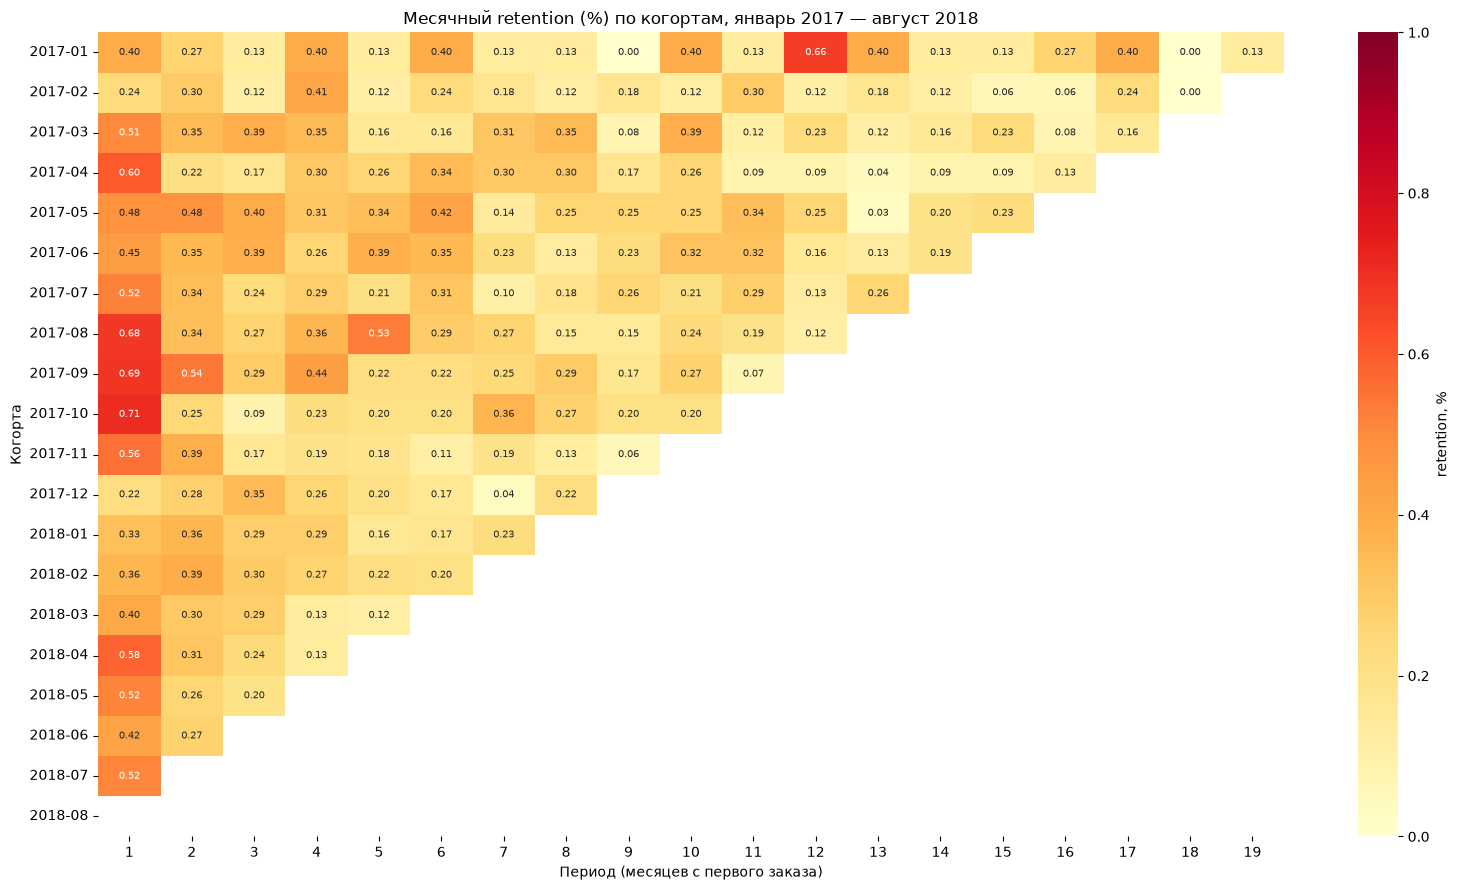

In [8]:
retention_matrix = cohort_data.pivot_table(index='cohort_month', columns='period', values='retention')
retention_matrix = retention_matrix.reindex(columns=range(retention_w.index.max() + 1))
# Если когорта уже прожила период, но никто не вернулся, это 0%, а не пустая ячейка
max_period = cohort_sizes.set_index('cohort_month')['max_period']
for p in retention_matrix.columns:
    observed = max_period.reindex(retention_matrix.index) >= p
    retention_matrix.loc[observed, p] = retention_matrix.loc[observed, p].fillna(0)
retention_matrix = retention_matrix.drop(columns=0)  # период 0 всегда 100%, он только мешает цветовой шкале

plt.figure(figsize=(16, 9))
sns.heatmap(retention_matrix, annot=True, fmt='.2f', cmap='YlOrRd', vmax=1,
            annot_kws={'size': 7}, cbar_kws={'label': 'retention, %'})
plt.title('Месячный retention (%) по когортам, январь 2017 — август 2018')
plt.xlabel('Период (месяцев с первого заказа)')
plt.ylabel('Когорта')
plt.tight_layout()
plt.savefig(IMG_PATH / 'retention_heatmap.png', dpi=150)
plt.show()

По тепловой карте видно, что ни одна когорта не возвращается заметно лучше остальных: все значения ниже 1%, максимум около 0,7%. Когорты 2018 года удерживаются не лучше когорт 2017-го, то есть удержание со временем не растёт.

## 3. Product/Market Fit

Смотрю, сколько заказов делает один клиент и как быстро возвращаются те, кто вернулся.

всего клиентов: 94,697
с 1 заказом: 91,823 (97.0%)
с >1 заказом: 2,874 (3.0%)
  из них второй заказ в тот же день: 893 (31% повторных)
    из них в пределах 5 минут после первого: 84%

вернулись в другой день: 2,029 (2.1% всех клиентов)
ни разу не вернулись в другой день: 97.9%
для сравнения, покупали только в одном календарном месяце: 98.2%


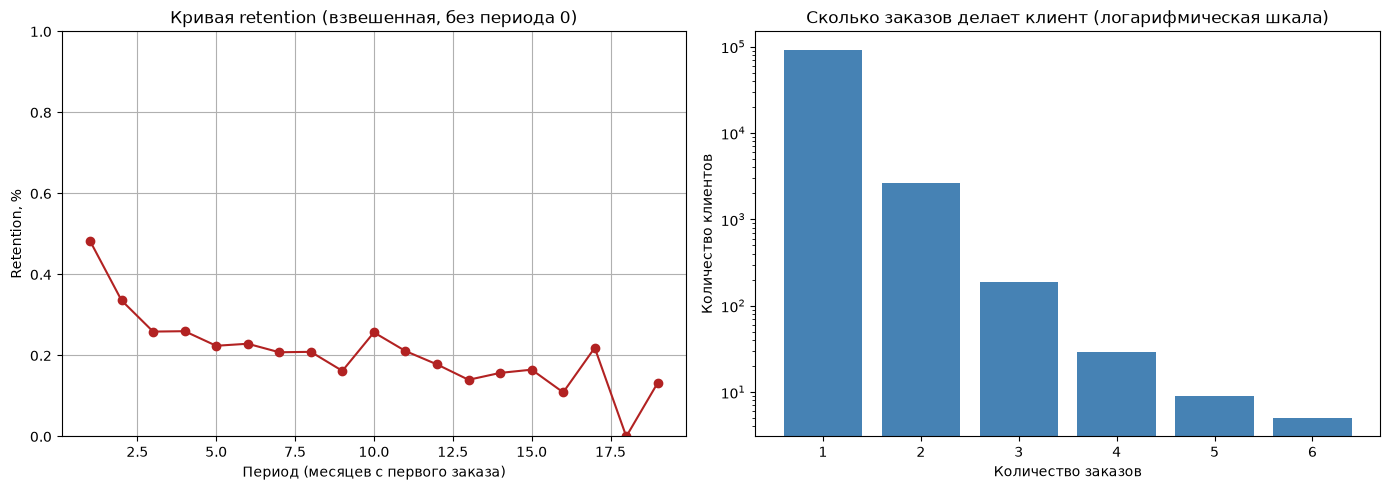

In [9]:
orders_sorted = orders_full.sort_values('order_purchase_timestamp').copy()
orders_sorted['order_number'] = orders_sorted.groupby('customer_unique_id').cumcount() + 1

first_order = orders_sorted[orders_sorted['order_number'] == 1].set_index('customer_unique_id')['order_purchase_timestamp']
second_order = orders_sorted[orders_sorted['order_number'] == 2].set_index('customer_unique_id')['order_purchase_timestamp']
days_to_second = (second_order - first_order.loc[second_order.index]).dt.days
minutes_to_second = (second_order - first_order.loc[second_order.index]).dt.total_seconds() / 60

orders_per_customer = orders_sorted.groupby('customer_unique_id')['order_id'].nunique()
total_customers = len(orders_per_customer)
repeat_customers = (orders_per_customer > 1).sum()
same_day = (days_to_second == 0).sum()

# Возврат — первый заказ в другой день, даже если перед ним был заказ в те же минуты, что и первый
orders_sorted['days_from_first'] = (orders_sorted['order_purchase_timestamp']
                                    - orders_sorted['customer_unique_id'].map(first_order)).dt.days
days_to_return = orders_sorted[orders_sorted['days_from_first'] > 0].groupby('customer_unique_id')['days_from_first'].min()
real_returns = len(days_to_return)
one_month = (orders_sorted.groupby('customer_unique_id')['order_month'].nunique() == 1).mean() * 100

print(f'всего клиентов: {total_customers:,}')
print(f'с 1 заказом: {(orders_per_customer == 1).sum():,} ({(orders_per_customer == 1).mean() * 100:.1f}%)')
print(f'с >1 заказом: {repeat_customers:,} ({repeat_customers / total_customers * 100:.1f}%)')
print(f'  из них второй заказ в тот же день: {same_day:,} ({same_day / repeat_customers * 100:.0f}% повторных)')
print(f'    из них в пределах 5 минут после первого: {(minutes_to_second[days_to_second == 0] <= 5).mean() * 100:.0f}%')
print()
print(f'вернулись в другой день: {real_returns:,} ({real_returns / total_customers * 100:.1f}% всех клиентов)')
print(f'ни разу не вернулись в другой день: {(1 - real_returns / total_customers) * 100:.1f}%')
print(f'для сравнения, покупали только в одном календарном месяце: {one_month:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

curve = retention_w.loc[1:, 'retention, %']
axes[0].plot(curve.index, curve.values, marker='o', color='firebrick')
axes[0].set_title('Кривая retention (взвешенная, без периода 0)')
axes[0].set_xlabel('Период (месяцев с первого заказа)')
axes[0].set_ylabel('Retention, %')
axes[0].set_ylim(0, 1)
axes[0].grid(True)

order_counts = orders_per_customer.value_counts().sort_index().head(6)
axes[1].bar(order_counts.index.astype(str), order_counts.values, color='steelblue')
axes[1].set_yscale('log')
axes[1].set_title('Сколько заказов делает клиент (логарифмическая шкала)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Количество клиентов')

plt.tight_layout()
plt.savefig(IMG_PATH / 'pmf_analysis.png', dpi=150)
plt.show()

Если считать по числу заказов, один заказ сделали 97,0% клиентов. Но треть «повторных» заказов оформлена в тот же день, что и первый, почти всегда в пределах нескольких минут. Это не возвращение клиента, а одна покупка, которая в данных записана как несколько заказов.

Поэтому возвратом я считаю заказ **в другой день**. Так вернулись 2,1% клиентов, а **97,9% не вернулись ни разу**. Это и есть правильная доля «одноразовых» покупателей. В первой версии было 98,2%: там считались календарные месяцы, и клиент, вернувшийся в том же месяце, тоже попадал в «одноразовые».

Кривая retention выходит на плато, но почти на нуле: около 0,2% в месяц. Признак Product/Market Fit — плато на заметном уровне, когда устойчивая доля клиентов продолжает покупать. Здесь такой доли нет, поэтому **PMF с точки зрения удержания нет**: площадка привлекает покупателей, но не превращает их в постоянных.

## 4. Ключевые метрики по месяцам

средний чек: 137.37 BRL
всего заказов: 97,905
общая выручка: 13,449,530 BRL
доля выручки от повторных заказов: 1.8%


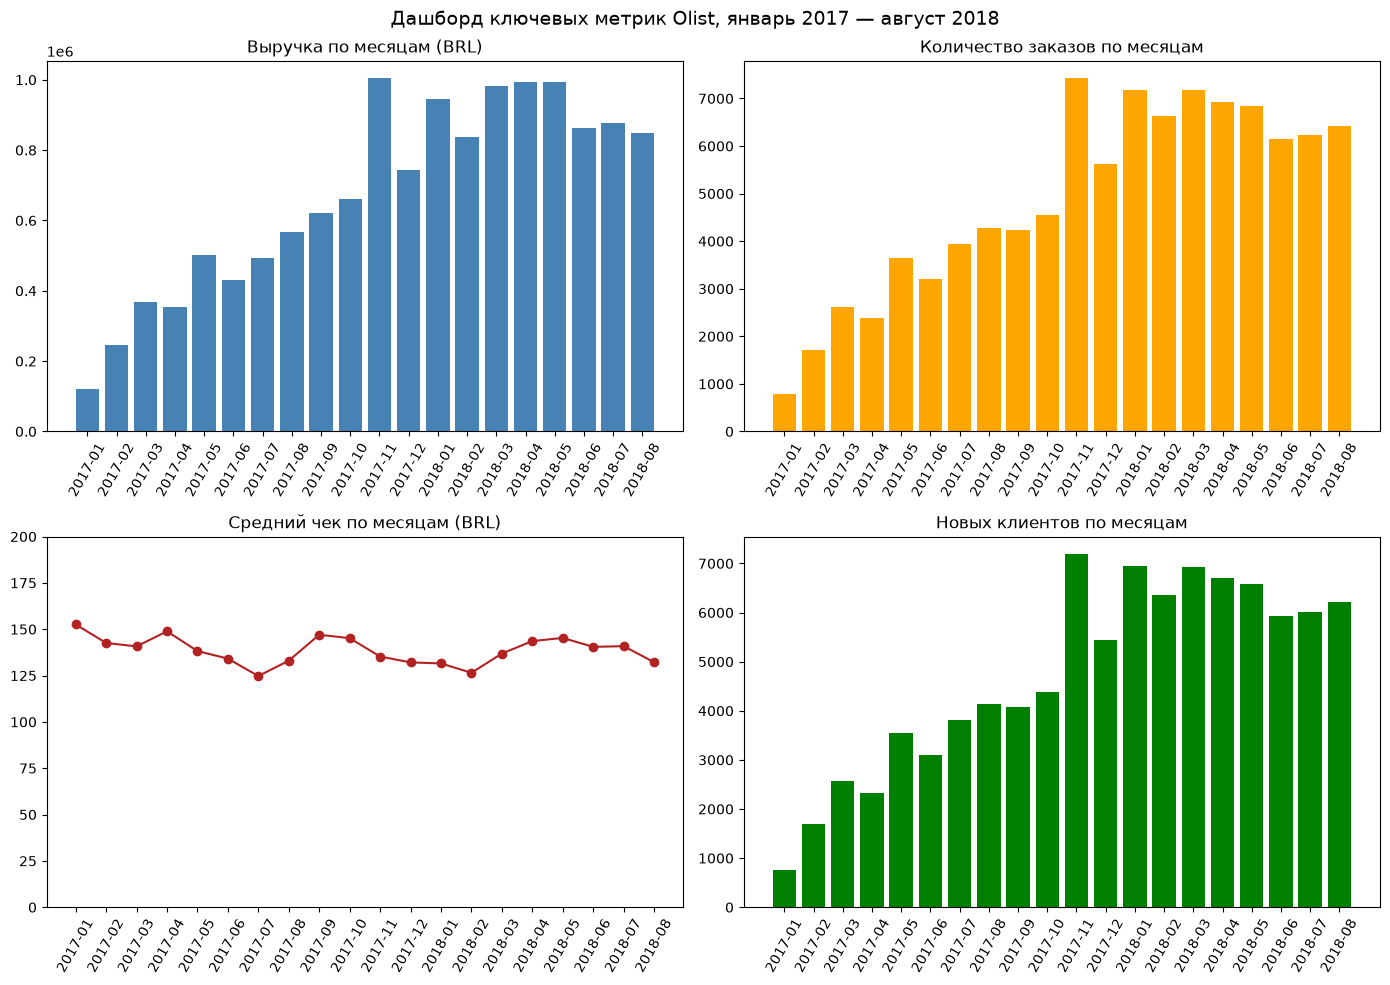

In [10]:
order_revenue = order_items.groupby('order_id')['price'].sum().rename('revenue')
monthly = window_orders.merge(order_revenue, on='order_id')
monthly['is_new'] = monthly['period'] == 0

revenue_by_month = monthly.groupby('order_month').agg(
    revenue=('revenue', 'sum'),
    n_orders=('order_id', 'nunique'),
    n_customers=('customer_unique_id', 'nunique'),
)
revenue_by_month['new_customers'] = monthly[monthly['is_new']].groupby('order_month')['customer_unique_id'].nunique()
revenue_by_month['avg_check'] = revenue_by_month['revenue'] / revenue_by_month['n_orders']
revenue_by_month.index = revenue_by_month.index.astype(str)

repeat_share = monthly.loc[~monthly['is_new'], 'revenue'].sum() / monthly['revenue'].sum() * 100
print(f"средний чек: {monthly['revenue'].mean():.2f} BRL")
print(f"всего заказов: {monthly['order_id'].nunique():,}")
print(f"общая выручка: {monthly['revenue'].sum():,.0f} BRL")
print(f"доля выручки от повторных заказов: {repeat_share:.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].bar(revenue_by_month.index, revenue_by_month['revenue'], color='steelblue')
axes[0, 0].set_title('Выручка по месяцам (BRL)')

axes[0, 1].bar(revenue_by_month.index, revenue_by_month['n_orders'], color='orange')
axes[0, 1].set_title('Количество заказов по месяцам')

axes[1, 0].plot(revenue_by_month.index, revenue_by_month['avg_check'], marker='o', color='firebrick')
axes[1, 0].set_ylim(0, 200)
axes[1, 0].set_title('Средний чек по месяцам (BRL)')

axes[1, 1].bar(revenue_by_month.index, revenue_by_month['new_customers'], color='green')
axes[1, 1].set_title('Новых клиентов по месяцам')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=60)

plt.suptitle('Дашборд ключевых метрик Olist, январь 2017 — август 2018', fontsize=14)
plt.tight_layout()
plt.savefig(IMG_PATH / 'metrics_dashboard.png', dpi=150)
plt.show()

### Самопроверка №2: реальна ли остановка роста

В первой версии я учитывал только доставленные заказы. Заказы последних недель ещё в пути, поэтому такой фильтр занижает конец периода и может нарисовать «остановку» там, где её нет. Сравниваю выручку за 2018 год по двум вариантам.

In [11]:
delivered_revenue = (
    window_orders[window_orders['order_status'] == 'delivered']
    .merge(order_revenue, on='order_id')
    .groupby('order_month')['revenue'].sum()
)
delivered_revenue.index = delivered_revenue.index.astype(str)

check = pd.DataFrame({
    'все состоявшиеся, BRL': revenue_by_month['revenue'],
    'только delivered, BRL': delivered_revenue,
})
check['разница, %'] = (1 - check['только delivered, BRL'] / check['все состоявшиеся, BRL']) * 100
check.loc['2018-01':].round(1)

,"все состоявшиеся, BRL","только delivered, BRL","разница, %"
order_month,,,
2018-01,945456.3,924645.0,2.2
2018-02,837895.4,826437.1,1.4
2018-03,981051.1,953356.2,2.8
2018-04,993593.0,973534.1,2.0
2018-05,992871.8,977544.7,1.5
2018-06,863265.5,856077.9,0.8
2018-07,878044.3,867953.5,1.1
2018-08,848860.1,838576.6,1.2


Разница между вариантами всего 1–3%, а выручка держится на одном уровне все 8 месяцев 2018 года. Значит, **остановка роста реальная, а не артефакт данных**. Артефактом был бы обрыв в сентябре–октябре 2018, но эти месяцы я уже исключил.

Что видно на дашборде:
- Выручка росла весь 2017 год, с 120 тыс. BRL в январе до 1 млн в ноябре (Black Friday). С января 2018 она стоит на месте: от 0,84 до 0,99 млн BRL в месяц.
- Средний чек стабилен, около 137 BRL, значит проблема не в стоимости заказа.
- Новых клиентов с марта по август 2018 стало примерно на 10% меньше.
- На повторные заказы приходится всего 1,8% выручки.

Вывод: выручка почти полностью держится на новых клиентах. Пока их приток рос, росла и выручка. Как только приток перестал расти, выручка остановилась, потому что вернувшиеся клиенты её не поддерживают.

## 5. RFM-сегментация

Делю клиентов на сегменты по трём признакам:
- **Recency** — сколько дней прошло с последней покупки;
- **Frequency** — сколько раз клиент покупал;
- **Monetary** — сколько денег он принёс.

Классический RFM делит каждый признак на 5 групп по квантилям. Сначала проверяю, получится ли это на наших данных.

In [12]:
SNAPSHOT = orders_full['order_purchase_timestamp'].max()  # дата, от которой считаю давность
order_level = orders_sorted.merge(order_revenue, on='order_id', how='left')

rfm = order_level.groupby('customer_unique_id').agg(
    last_order=('order_purchase_timestamp', 'max'),
    frequency=('days_from_first', 'nunique'),  # заказы в одни и те же минуты считаются одной покупкой
    monetary=('revenue', 'sum'),
)
rfm['recency'] = (SNAPSHOT - rfm['last_order']).dt.days

print('Сколько покупок делают клиенты:')
print(rfm['frequency'].value_counts().sort_index().head(4).to_string())
print()
try:
    pd.qcut(rfm['frequency'], 5)
except ValueError as e:
    print('Квинтили по Frequency построить нельзя:', e)

Сколько покупок делают клиенты:
frequency
1    92668
2     1875
3      123
4       17

Квинтили по Frequency построить нельзя: Bin edges must be unique: Index([1.0, 1.0, 1.0, 1.0, 1.0, 16.0], dtype='float64', name='frequency').
You can drop duplicate edges by setting the 'duplicates' kwarg


Классический вариант не работает: у 97,9% клиентов ровно одна покупка, поэтому все границы квинтилей по Frequency совпадают. Адаптирую метод под данные:
- **Frequency:** одна покупка или две и больше. Это тот же критерий возврата, что и в разделе 3.
- **Recency:** пороги беру из времени до возврата, а не из квантилей. До 90 дней — здесь медиана возврата (75 дней). 91–180 дней — к 180 дням случается три четверти всех возвратов. Больше 180 дней — клиент, скорее всего, уже не вернётся.
- **Monetary:** три равные по численности группы (терцили).

                    клиентов    выручка  сумма_на_клиента  дней_с_покупки  доля клиентов, %  доля выручки, %
segment                                                                                                     
Постоянные              1091   301134.4             276.0            87.5               1.2              2.2
Бывшие постоянные        938   248599.2             265.0           309.9               1.0              1.8
Новые, высокий чек      5808  1752913.1             301.8            45.0               6.1             13.0
Новые                  12407   774167.8              62.4            43.8              13.1              5.8
Остывающие             19584  2803026.0             143.1           136.6              20.7             20.8
Потерянные             54869  7568230.8             137.9           337.6              57.9             56.3


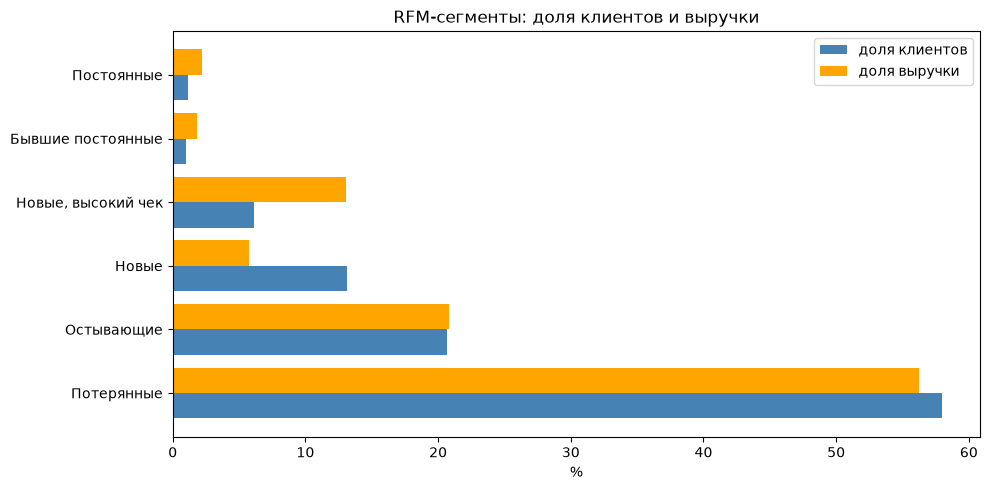

In [13]:
rfm['M'] = pd.qcut(rfm['monetary'], 3, labels=['низкий', 'средний', 'высокий'])

conditions = [
    (rfm['frequency'] >= 2) & (rfm['recency'] <= 180),
    rfm['frequency'] >= 2,
    (rfm['recency'] <= 90) & (rfm['M'] == 'высокий'),
    rfm['recency'] <= 90,
    rfm['recency'] <= 180,
]
segments = ['Постоянные', 'Бывшие постоянные', 'Новые, высокий чек', 'Новые', 'Остывающие']
rfm['segment'] = np.select(conditions, segments, default='Потерянные')

segment_order = segments + ['Потерянные']
rfm_summary = rfm.groupby('segment').agg(
    клиентов=('monetary', 'size'),
    выручка=('monetary', 'sum'),
    сумма_на_клиента=('monetary', 'mean'),
    дней_с_покупки=('recency', 'mean'),
).reindex(segment_order)
rfm_summary['доля клиентов, %'] = rfm_summary['клиентов'] / rfm_summary['клиентов'].sum() * 100
rfm_summary['доля выручки, %'] = rfm_summary['выручка'] / rfm_summary['выручка'].sum() * 100
print(rfm_summary.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(segment_order))
ax.barh(y + 0.2, rfm_summary['доля клиентов, %'], height=0.4, color='steelblue', label='доля клиентов')
ax.barh(y - 0.2, rfm_summary['доля выручки, %'], height=0.4, color='orange', label='доля выручки')
ax.set_yticks(y)
ax.set_yticklabels(segment_order)
ax.invert_yaxis()
ax.set_xlabel('%')
ax.set_title('RFM-сегменты: доля клиентов и выручки')
ax.legend()
plt.tight_layout()
plt.savefig(IMG_PATH / 'rfm_segments.png', dpi=150)
plt.show()

Что показала сегментация:
- **Больше половины базы — «потерянные»:** одна покупка больше полугода назад. На них пришлась и больше половины выручки окна, но возвращаются такие клиенты редко, ведь три четверти возвратов случаются в первые 180 дней.
- **Постоянных клиентов (вместе с бывшими) около 2%,** они дают около 4% выручки. Каждый из них приносит примерно вдвое больше денег, чем разовый покупатель, но их слишком мало, чтобы влиять на выручку.
- **«Новые, высокий чек»** — 6% клиентов и 13% выручки.

Проверяю, стоит ли напоминание отправлять именно клиентам с высоким чеком: вдруг они возвращаются чаще. Считаю долю вернувшихся за 90 дней (как в будущем эксперименте) по сумме первой покупки, только среди клиентов, у которых было 90 дней наблюдения.

In [14]:
first_purchase_value = order_level[order_level['days_from_first'] == 0].groupby('customer_unique_id')['revenue'].sum()
observed = first_order[first_order <= SNAPSHOT - pd.Timedelta(days=90)].index
returned_90 = days_to_return.reindex(observed).le(90)

value_group = pd.qcut(first_purchase_value.reindex(observed), 3,
                      labels=['низкая', 'средняя', 'высокая']).rename('сумма первой покупки')
(returned_90.groupby(value_group).mean() * 100).round(2).rename('вернулись за 90 дней, %').to_frame()

,"вернулись за 90 дней, %"
сумма первой покупки,
низкая,1.31
средняя,1.25
высокая,1.30


Доля вернувшихся почти не зависит от суммы первой покупки. Значит, ограничивать напоминание клиентами с высоким чеком нет смысла: больше возвратов это не даст. Напоминание нужно отправлять всем новым клиентам, а сегменты использовать для другого: «потерянных» нет смысла догонять напоминаниями, деньги на них лучше потратить на привлечение.

## 6. Приоритизация гипотез по ICE

                                       Гипотеза  Impact  Confidence  Ease  ICE
H2: Email/push-напоминание после первого заказа       8           7     7  392
                        H1: Упростить онбординг       7           6     8  336
                       H3: Программа лояльности       6           4     3   72


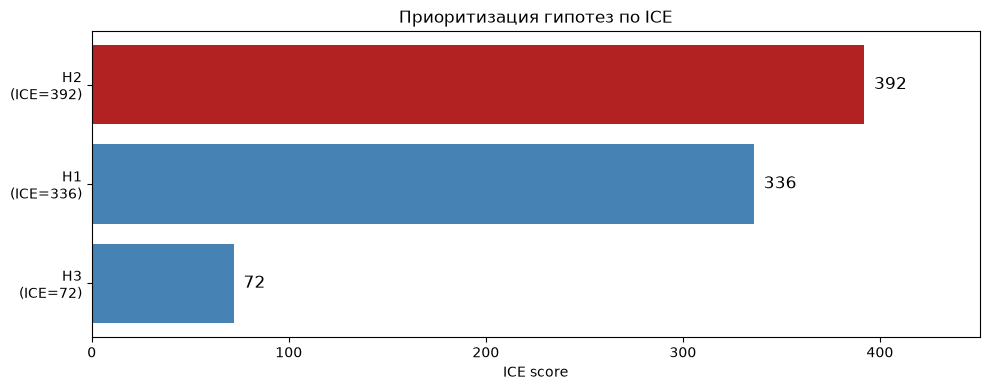

In [15]:
hypotheses = pd.DataFrame({
    'Гипотеза': [
        'H1: Упростить онбординг',
        'H2: Email/push-напоминание после первого заказа',
        'H3: Программа лояльности',
    ],
    'Impact': [7, 8, 6],
    'Confidence': [6, 7, 4],
    'Ease': [8, 7, 3],
})
hypotheses['ICE'] = hypotheses['Impact'] * hypotheses['Confidence'] * hypotheses['Ease']
hypotheses = hypotheses.sort_values('ICE', ascending=False)
print(hypotheses.to_string(index=False))

plot_data = hypotheses.sort_values('ICE')
labels = [f'{h.split(":")[0]}\n(ICE={s})' for h, s in zip(plot_data['Гипотеза'], plot_data['ICE'])]
colors = ['firebrick' if s == plot_data['ICE'].max() else 'steelblue' for s in plot_data['ICE']]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(labels, plot_data['ICE'], color=colors)
for bar, val in zip(bars, plot_data['ICE']):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height() / 2, str(val), va='center', fontsize=12)
ax.set_title('Приоритизация гипотез по ICE')
ax.set_xlabel('ICE score')
ax.set_xlim(0, plot_data['ICE'].max() * 1.15)
plt.tight_layout()
plt.savefig(IMG_PATH / 'ice_chart.png', dpi=150)
plt.show()

Наибольший балл у гипотезы H2 (392), её я выбираю для проверки. Она бьёт в главную проблему, низкий retention, и при этом относительно проста в реализации. Гипотеза H3 набрала меньше всего из-за сложности внедрения и неопределённого эффекта.

## 7. Метрики для гипотезы H2

### Самопроверка №3: когда отправлять напоминание

В первой версии я обосновал напоминание через 30 дней тем, что медиана времени до повторного заказа составляет 26 дней. Перепроверил и нашёл ошибку: медиана была посчитана только по клиентам, вернувшимся в соседний календарный месяц. У них разрыв по определению не больше двух месяцев, поэтому медиана заведомо получается короткой, а все, кто вернулся позже, в расчёт не попали.

Если посчитать по всем вернувшимся, получится 28 дней, что как будто подтверждает старый результат. Но здесь вторая ловушка: треть «вторых заказов» сделана в те же минуты, что и первый (см. раздел 3). Эти нули тянут медиану вниз. Поэтому для каждого клиента беру первый заказ в другой день (`days_to_return` из раздела 3), даже если перед ним был заказ в те же минуты.

вернулись в другой день: 2,029 клиентов
медиана дней до возврата: 75
проверка порога: если исключать только заказы в течение часа после первого, медиана 71 дней
25% / 75% квантили: 24 / 175 дней
вернулись в течение 30 дней: 29% вернувшихся
вернулись в течение 60 дней: 45% вернувшихся
вернулись в течение 90 дней: 55% вернувшихся


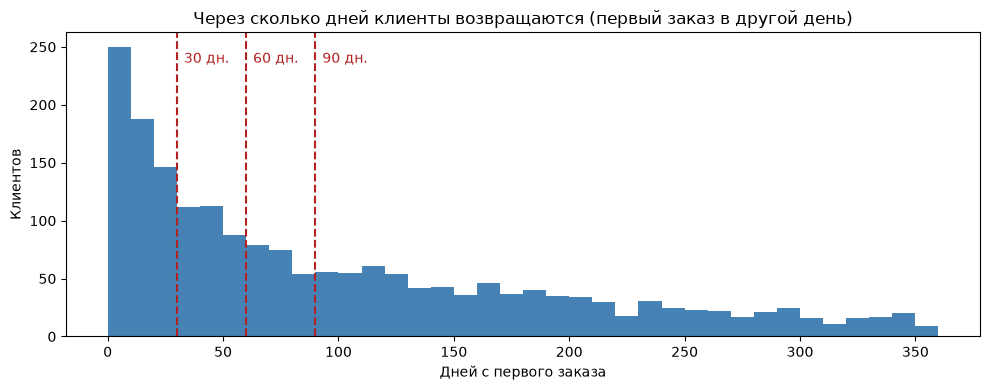

In [16]:
real_gap = days_to_return

print(f'вернулись в другой день: {len(real_gap):,} клиентов')
print(f'медиана дней до возврата: {real_gap.median():.0f}')
alt = orders_sorted[(orders_sorted['order_purchase_timestamp'] - orders_sorted['customer_unique_id'].map(first_order))
                    > pd.Timedelta(hours=1)].groupby('customer_unique_id')['days_from_first'].min()
print(f'проверка порога: если исключать только заказы в течение часа после первого, медиана {alt.median():.0f} дней')
print(f'25% / 75% квантили: {real_gap.quantile(0.25):.0f} / {real_gap.quantile(0.75):.0f} дней')
for d in [30, 60, 90]:
    print(f'вернулись в течение {d} дней: {(real_gap <= d).mean() * 100:.0f}% вернувшихся')

plt.figure(figsize=(10, 4))
plt.hist(real_gap, bins=range(0, 361, 10), color='steelblue')
for d in [30, 60, 90]:
    plt.axvline(d, color='firebrick', linestyle='--')
    plt.text(d + 3, plt.ylim()[1] * 0.9, f'{d} дн.', color='firebrick')
plt.title('Через сколько дней клиенты возвращаются (первый заказ в другой день)')
plt.xlabel('Дней с первого заказа')
plt.ylabel('Клиентов')
plt.tight_layout()
plt.savefig(IMG_PATH / 'days_to_second_order.png', dpi=150)
plt.show()

Медиана — **75 дней**, а не 26. Результат почти не зависит от того, где провести границу «той же покупки»: если исключать только заказы в течение часа после первого, медиана 71 день. В течение 30 дней возвращается меньше трети вернувшихся. Значит, напоминание через 30 дней может прийти раньше, чем у клиента возникнет потребность. Срок не нужно угадывать, его стоит проверить в эксперименте: сравнить напоминание через 30 и через 60 дней.

### Дизайн эксперимента

- **Аудитория:** все новые клиенты, без отбора по сумме чека. RFM-анализ показал, что вероятность возврата от неё не зависит.
- **Группы:** контроль (без напоминания), напоминание через 30 дней, напоминание через 60 дней.
- **Основная метрика:** доля новых клиентов, которые вернулись (сделали заказ в другой день) в течение 90 дней после первого. Окно в 90 дней оставляет обеим группам время отреагировать на напоминание.
- **Контрольные метрики:** отписки от рассылки, жалобы на спам, средний чек второго заказа.

Считаю базовый уровень основной метрики и размер выборки.

In [17]:
LAST_DATE = orders_full['order_purchase_timestamp'].max()
WINDOW = 90

# Только клиенты, у которых после первого заказа прошло не меньше 90 дней наблюдения
observable = first_order[first_order <= LAST_DATE - pd.Timedelta(days=WINDOW)]
returned = real_gap.reindex(observable.index).le(WINDOW).sum()
baseline = returned / len(observable)
print(f'клиентов с полными {WINDOW} днями наблюдения: {len(observable):,} (первый заказ не позже {(LAST_DATE - pd.Timedelta(days=WINDOW)).date()})')
print(f'базовый уровень: {baseline * 100:.2f}% новых клиентов возвращаются за {WINDOW} дней')

new_per_month = revenue_by_month['new_customers'].loc['2018-03':].mean()
per_group_month = new_per_month / 3
print(f'новых клиентов в месяц (март–август 2018): {new_per_month:,.0f}, на одну группу: {per_group_month:,.0f}')


def sample_size(p1, p2, alpha=0.05, power=0.8):
    """Размер каждой группы для сравнения двух долей (двусторонний тест)."""
    z_a = NormalDist().inv_cdf(1 - alpha / 2)
    z_b = NormalDist().inv_cdf(power)
    p_bar = (p1 + p2) / 2
    n = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p2 - p1) ** 2
    return int(np.ceil(n))


plan = []
for uplift in [0.5, 1.0, 1.5]:
    target = baseline * (1 + uplift)
    n = sample_size(baseline, target)
    plan.append({'рост метрики': f'+{uplift:.0%}',
                 'цель, %': round(target * 100, 2),
                 'клиентов в группе': n,
                 'месяцев набора': round(n / per_group_month, 1)})
pd.DataFrame(plan)

клиентов с полными 90 днями наблюдения: 76,485 (первый заказ не позже 2018-05-31)
базовый уровень: 1.29% новых клиентов возвращаются за 90 дней
новых клиентов в месяц (март–август 2018): 6,393, на одну группу: 2,131


,рост метрики,"цель, %",клиентов в группе,месяцев набора
0,+50%,1.93,5996,2.8
1,+100%,2.58,1792,0.8
2,+150%,3.22,926,0.4


Базовый уровень низкий, поэтому эксперимент может поймать только крупный эффект. Таблица показывает, сколько месяцев нужно набирать клиентов, чтобы заметить рост метрики на 50, 100 или 150%. К этому сроку надо добавить ещё 90 дней наблюдения за последней партией клиентов.

**Почему цель — удвоение.** Это не прогноз и не требование бизнеса, а минимальный эффект, который тест надёжно поймает примерно за месяц набора при нашем трафике. Чтобы заметить рост на 50%, набор пришлось бы вести почти три месяца. Если напоминание даст меньше удвоения, тест покажет «разницы не нашли», и это тоже результат.

Чтобы понимать, стоит ли игра свеч, считаю, сколько денег даст успех эксперимента.

In [18]:
avg_check = monthly['revenue'].mean()
revenue_now = revenue_by_month['revenue'].loc['2018-06':].mean()

for uplift in [0.5, 1.0]:
    extra_orders = new_per_month * baseline * uplift
    extra_revenue = extra_orders * avg_check
    print(f'рост возвратов +{uplift:.0%}: +{extra_orders:.0f} повторных заказов в месяц, '
          f'+{extra_revenue:,.0f} BRL, это +{extra_revenue / revenue_now * 100:.1f}% месячной выручки')

lost_new = (revenue_by_month.loc['2018-03', 'new_customers'] - revenue_by_month.loc['2018-06':, 'new_customers'].mean())
print(f'для сравнения: падение притока новых клиентов с марта — около {lost_new:,.0f} человек в месяц, '
      f'это примерно {lost_new * avg_check:,.0f} BRL выручки в месяц')

рост возвратов +50%: +41 повторных заказов в месяц, +5,655 BRL, это +0.7% месячной выручки
рост возвратов +100%: +82 повторных заказов в месяц, +11,311 BRL, это +1.3% месячной выручки
для сравнения: падение притока новых клиентов с марта — около 883 человек в месяц, это примерно 121,255 BRL выручки в месяц


Даже удвоение возвратов даёт около 80 дополнительных заказов и 1,3% выручки в месяц. А падение притока новых клиентов с марта по лето 2018 стоит площадке около 120 тыс. BRL в месяц, примерно в 10 раз больше. Значит, напоминание стоит проверить, потому что это дёшево, но **само по себе оно рост выручки не вернёт**. Главный рычаг — приток новых клиентов.

## 8. Итоговый отчёт

Петя попросил разобраться, почему выручка стоит на месте. Я посмотрел данные с января 2017 по август 2018, и вот что нашёл.

**Главная проблема:** выручка держится почти только на новых клиентах, а их приток перестал расти. Клиенты не возвращаются: **97,9%** покупателей ни разу не пришли снова, а во второй месяц после первой покупки возвращается **0,48%**, меньше 5 из 1 000. Это классическое «дырявое ведро»: пока приток новых клиентов рос, ведро наполнялось, а когда приток остановился, остановилась и выручка.

**Что показали данные:**
- Retention первого месяца 0,48%, дальше кривая выходит на плато около 0,2%. Плато почти на нуле, поэтому PMF с точки зрения удержания нет.
- На повторные заказы приходится всего 1,8% выручки. Пока приток новых клиентов рос (весь 2017 год), росла и выручка. С января 2018 приток перестал расти, и выручка остановилась на уровне 0,84–0,99 млн BRL в месяц.
- С марта по август 2018 новых клиентов стало примерно на 10% меньше.
- Средний чек стабилен, около 137 BRL, проблема не в нём.
- Остановка роста реальная: я проверил, что её не создают неполные месяцы и недоставленные заказы.
- RFM-сегментация: больше половины базы — «потерянные» клиенты с одной покупкой больше полугода назад. Постоянных около 2%, они дают около 4% выручки. Вероятность вернуться не зависит от суммы первой покупки.

**Что предлагаю:**
1. **Главное — разобраться с притоком новых клиентов.** Это самый большой рычаг: падение притока с марта стоит около 120 тыс. BRL в месяц, примерно в 10 раз больше, чем даст даже удвоение возвратов. Нужно понять, какие каналы привлечения просели. Для этого нужны данные маркетинга, в датасете их нет.
2. **Параллельно — дешёвый эксперимент с напоминанием** после первого заказа (гипотеза H2, наибольший ICE). Срок отправки проверить, а не угадывать: вернувшиеся клиенты приходят в среднем через 75 дней, и в течение 30 дней — меньше трети из них. Отправлять всем новым клиентам, без отбора по чеку. Ожидания нужно держать реалистичными: даже удвоение возвратов даёт около +1,3% выручки.

**Как проверим H2:** A/B/C-тест с тремя группами: без напоминания, напоминание через 30 дней и через 60 дней. Основная метрика — доля новых клиентов, вернувшихся в течение 90 дней (сейчас 1,29%). Цель — удвоение, до 2,6%: это минимальный эффект, который тест поймает примерно за месяц набора. Контрольные метрики: отписки, жалобы на спам, средний чек повторного заказа.

**Следующие шаги:**
1. Запросить у маркетинга данные по каналам привлечения и найти, где просел приток новых клиентов с марта 2018.
2. Запустить A/B/C-тест с напоминанием: набор клиентов около месяца и 90 дней наблюдения.
3. Начать собирать NPS и провести опрос клиентов, чтобы понять, почему они не возвращаются. Сейчас таких данных нет.

## Самопроверка: что изменилось по сравнению с первой версией

| Что | Было | Стало | Причина |
|---|---|---|---|
| Retention первого месяца | 5,45% | **0,48%** | Простое среднее по когортам: когорта декабря 2016 из одного клиента с retention 100% весила как когорта из 7 000 человек. Теперь среднее взвешенное. |
| Период анализа | все месяцы, только `delivered` | январь 2017 — август 2018, все состоявшиеся заказы | 2016 год и сентябрь–октябрь 2018 неполные. Недоставленные заказы занижали конец периода. |
| Остановка роста выручки | предположение | подтверждена | Проверил, что разница между «delivered» и всеми заказами 1–3%, а плато длится 8 месяцев. |
| Доля клиентов с одним заказом | 98,2% | **97,9%** | Первая версия считала календарные месяцы и не видела возвратов в том же месяце. Подсчёт по заказам (97,0%) ошибается в другую сторону: считает возвратом покупку, записанную несколькими заказами. Правильно — клиенты, ни разу не вернувшиеся в другой день. |
| Время до повторного заказа | 26 дней | **75 дней** | Медиана считалась только по вернувшимся в соседний календарный месяц, где разрыв не больше двух месяцев. По всем вернувшимся выходит 28 дней, но только из-за заказов, оформленных в те же минуты, что и первый. Без них медиана 75 дней. |
| Цель A/B-теста | 5,45% → 10% | 1,29% → 2,6% (возврат за 90 дней) | Старая база была неверной. Удвоение — минимальный эффект, который тест поймает примерно за месяц набора. |
| Главный рычаг роста | напоминания (H2) | приток новых клиентов, H2 — дешёвый дополнительный тест | Посчитал эффект H2 в деньгах: даже удвоение возвратов — около +1,3% выручки. |
| Сегментация клиентов | не было | RFM с адаптированными порогами | Классические квинтили построить нельзя: у 97,9% клиентов одна покупка. Frequency свёл к «1 или 2+», пороги Recency взял из времени до возврата. |

Главный урок: прежде чем делать выводы, нужно проверять, полные ли периоды на краях данных и какой вес у групп, которые усредняются.